# Regression vs. flow: from affine to nonlinear conditional means

**Research ladder.** Part 0 保留原始线性基准；Part 1 改为非线性条件均值，并依次检查模型欠拟合、已知非线性特征、以及可训练条件表示。结果不预设 flow 优势。

## Part 0 — original affine baseline

一个可解析的 JAX toy experiment：检查 **训练更新次数 $k$** 如何影响生成 action 到条件 manifold 的距离，并单独检查 **生成时间 $t$** 上的轨迹。

数据为
$$X,Z\overset{\mathrm{iid}}\sim\mathcal N(0,1),\qquad
Y=(X+Z,\ X+1)^\top.$$
给定 $x$，$\mathcal M_x=\{(s,x+1):s\in\mathbb R\}$，切向是 $y_1$，法向是 $y_2$。
$$\mathcal E(k)=\mathbb E[(\widehat Y_{k,2}-X-1)^2].$$

**范围。** 无 neural network、无 action perturbation、无 KNN 估计。两种模型都用 vanilla population GD；这是优化动力学实验，不是有限样本/SGD 实验，也不预设 flow 会更快。所有 $x$ 混合后的 action 分布是满维的，评估必须条件于 $x$。

从上到下 **Run All**。运行依赖仅 `jax`、`numpy`、`matplotlib`，CPU 即可。安装可在单独 cell 中运行 `%pip install -U jax numpy matplotlib`。修改下一格配置后重新 Run All。

In [1]:
from functools import partial

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

jax.config.update("jax_enable_x64", True)

SEED = 7
DEGREE = 3                 # Flow: (DEGREE + 1) time basis functions.
TRAIN_STEPS = 6000
STEP_FRACTION = 0.8         # Each model uses eta = fraction / lambda_max(H).
ODE_STEPS = 256             # Fixed-step RK4 on the entire interval [0, 1].
X_INSPECT = 0.5

assert DEGREE >= 0 and TRAIN_STEPS >= 1 and ODE_STEPS >= 1
assert 0 < STEP_FRACTION < 2
REG, FLOW, ORACLE = "#D55E00", "#0072B2", "#009E73"
plt.rcParams.update({
    "figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.16,
    "figure.constrained_layout.use": True,
})
print(f"JAX {jax.__version__} | {jax.devices()} | float64 enabled")

JAX 0.11.2 | [CpuDevice(id=0)] | float64 enabled


## 1. Inspect the data and conditional manifolds

左图把不同 $x$ 的 action 混在一起，仅用于观察数据；右图分别固定三个 $x$。每条水平直线都是对应的 $\mathcal M_x$。生成数据的随机性完全沿切向，法向关系 $Y_2=X+1$ 没有标签噪声。

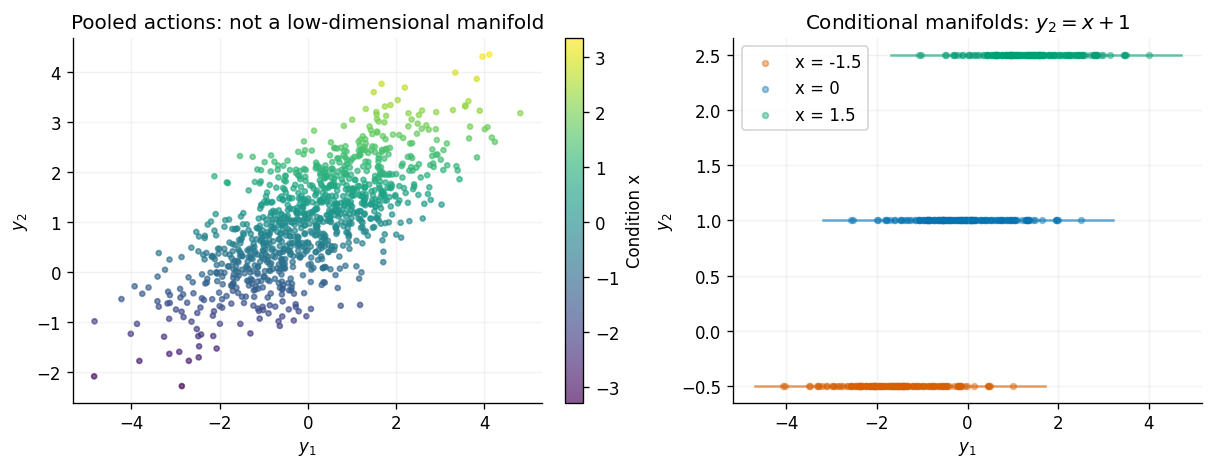

In [2]:
def sample_data(key, n):
    x, z = jax.random.normal(key, (2, n))
    y = jnp.stack([x + z, x + 1], axis=-1)
    return x, y


x_data, y_data = sample_data(jax.random.key(SEED), 1000)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
points = axes[0].scatter(*np.asarray(y_data).T, c=np.asarray(x_data),
                         cmap="viridis", s=9, alpha=0.65, rasterized=True)
fig.colorbar(points, ax=axes[0], label="Condition x")
axes[0].set(title="Pooled actions: not a low-dimensional manifold", xlabel="$y_1$", ylabel="$y_2$")
z_show = np.asarray(jax.random.normal(jax.random.key(SEED + 1), (160,)))
for x0, color in zip([-1.5, 0.0, 1.5], [REG, FLOW, ORACLE]):
    axes[1].plot([x0 - 3.2, x0 + 3.2], [x0 + 1] * 2, color=color, alpha=0.6)
    axes[1].scatter(x0 + z_show, np.full_like(z_show, x0 + 1), s=12,
                    alpha=0.4, color=color, label=f"x = {x0:g}")
axes[1].set(title="Conditional manifolds: $y_2=x+1$", xlabel="$y_1$", ylabel="$y_2$")
axes[1].legend()
plt.show()

## 2. Define both training recipes

**Regression.** $f_R(x)=W_R[x,1]^\top$，最小化 $\mathcal L_R=\frac12\mathbb E\|f_R(X)-Y\|^2$。零初始化下，population GD 给出
$$\mathcal E_R(k)=2(1-\eta_R)^{2k},\qquad \min\mathcal L_R=\tfrac12.$$

**Flow matching.** 取独立 $\varepsilon\sim\mathcal N(0,I_2)$ 和 $t\sim\mathcal U(0,1)$，令
$$Y_t=(1-t)\varepsilon+tY,\qquad
\mathcal L_F=\tfrac12\mathbb E\|v_\Theta(Y_t,t,X)-(Y-\varepsilon)\|^2.$$
模型是
$$v_\Theta(a,t,x)=W_\Theta(t)[a_1,a_2,x,1]^\top,\qquad
W_\Theta(t)=\sum_{j=0}^{p}b_j(t)\Theta_j.$$
$b_j$ 是在 $[0,1]$ 上归一化的 shifted Legendre 多项式；每个 $\Theta_j$ 都是可训练的完整 $2\times4$ 矩阵。不输入 manifold projector，也不强制输出在 manifold 上。

**终点选择。** 用这个有限、多项式时间参数化，把普通 ODE 从 $0$ 积分到 $1$，不加 terminal denoising 或 projection。真实最优法向场是 $(x+1-a_2)/(1-t)$，有限多项式无法精确表达这个奇异终点。因此额外计算**本模型类的最小二乘最优解**：其生成误差是参考值，并非 off-manifold error 的理论下界。

### Exact population losses, without sampling noise

令 $q=(X,Z,\varepsilon_1,\varepsilon_2,1)^\top$，则 $\mathbb E[qq^\top]=I_5$。若残差为 $Rq$，有 $\mathbb E\|Rq\|^2=\|R\|_F^2$。下面用简单的系数矩阵精确积分掉高斯变量，只对 $t$ 做 Gauss–Legendre quadrature；节点数足以精确积分这里的多项式 loss。矩阵是合成数据分布的表达，不是提供给模型的额外 manifold 监督。

In [3]:
def time_basis(t):
    u = 2 * jnp.asarray(t) - 1
    values = [jnp.ones_like(u)]
    if DEGREE >= 1:
        values.append(u)
    for n in range(1, DEGREE):
        values.append(((2 * n + 1) * u * values[-1] - n * values[-2]) / (n + 1))
    return jnp.stack(values, axis=-1) * jnp.sqrt(2 * jnp.arange(DEGREE + 1) + 1)


# All matrices below map q = [x, z, eps_1, eps_2, 1] to a random variable.
Y_MAP = jnp.array([[1., 1., 0., 0., 0.], [1., 0., 0., 0., 1.]])
EPS_MAP = jnp.eye(5)[2:4]
REG_FEATURES = jnp.eye(5)[jnp.array([0, 4])]
V_MAP = Y_MAP - EPS_MAP
nodes, weights = np.polynomial.legendre.leggauss(max(16, DEGREE + 2))
T_QUAD, T_WEIGHTS = jnp.asarray((nodes + 1) / 2), jnp.asarray(weights / 2)
interpolated = (1 - T_QUAD[:, None, None]) * EPS_MAP + T_QUAD[:, None, None] * Y_MAP
features = jnp.concatenate([
    interpolated, jnp.broadcast_to(REG_FEATURES, (len(nodes), 2, 5))
], axis=1)
FLOW_FEATURES = (time_basis(T_QUAD)[:, :, None, None] * features[:, None]).reshape(len(nodes), -1, 5)


def regression_loss(w):
    return 0.5 * jnp.sum((w @ REG_FEATURES - Y_MAP) ** 2)


def flow_loss(theta):
    residual = jnp.einsum("df,qfl->qdl", theta, FLOW_FEATURES) - V_MAP
    return 0.5 * jnp.sum(T_WEIGHTS[:, None, None] * residual ** 2)


H_REG = REG_FEATURES @ REG_FEATURES.T
H_FLOW = jnp.einsum("q,qfl,qgl->fg", T_WEIGHTS, FLOW_FEATURES, FLOW_FEATURES)
G_FLOW = jnp.einsum("q,dl,qfl->df", T_WEIGHTS, V_MAP, FLOW_FEATURES)
W_REG_STAR = jnp.array([[1., 0.], [1., 1.]])
THETA_STAR = jnp.linalg.solve(H_FLOW, G_FLOW.T).T
ETA_REG = float(STEP_FRACTION / jnp.linalg.eigvalsh(H_REG)[-1])
ETA_FLOW = float(STEP_FRACTION / jnp.linalg.eigvalsh(H_FLOW)[-1])
print(f"Regression: {W_REG_STAR.size} parameters, eta = {ETA_REG:.4f}")
print(f"Flow: {THETA_STAR.size} parameters, eta = {ETA_FLOW:.4f}")
print(f"Flow Hessian condition number = {float(jnp.linalg.cond(H_FLOW)):.1f}")
print(f"Class-optimal losses: regression = {float(regression_loss(W_REG_STAR)):.6f}, "
      f"flow = {float(flow_loss(THETA_STAR)):.6f}")

Regression: 4 parameters, eta = 0.8000
Flow: 32 parameters, eta = 0.2279
Flow Hessian condition number = 611.5
Class-optimal losses: regression = 0.500000, flow = 0.812145


## 3. Train with JAX gradients

两边都从零参数开始，用 $\eta_m=\alpha/\lambda_{\max}(H_m)$；默认 $\alpha=0.8$。这控制了各自最快曲率方向的步长，但不会消除 conditioning 差异。Regression 初始输出为 $0$；零 velocity 的 flow 初始输出为 $\varepsilon$，所以初始法向误差分别为 $2$ 和 $3$。

横轴是 **population GD 更新次数**，不是 wall time 或相同 FLOPs。Flow 的参数更多、时间表示不同，这个实验不能单独支持跨模型的普遍速度结论。`lax.scan` 只负责把普通 GD 循环编译；无 optimizer framework。

In [4]:
def train(loss_fn, initial, learning_rate):
    @jax.jit
    def run(params):
        def step(params, _):
            params = params - learning_rate * jax.grad(loss_fn)(params)
            return params, params
        _, history = jax.lax.scan(step, params, None, length=TRAIN_STEPS)
        return jnp.concatenate([params[None], history])
    return run(initial)


reg_history = train(regression_loss, jnp.zeros_like(W_REG_STAR), ETA_REG)
flow_history = train(flow_loss, jnp.zeros_like(THETA_STAR), ETA_FLOW)
reg_losses = np.asarray(jax.vmap(regression_loss)(reg_history))
flow_losses = np.asarray(jax.vmap(flow_loss)(flow_history))
CHECKPOINTS = np.unique(np.r_[0, np.arange(1, min(21, TRAIN_STEPS + 1)),
    np.geomspace(1, TRAIN_STEPS, 80).astype(int), TRAIN_STEPS])
print(f"Finished {TRAIN_STEPS:,} population GD updates per model.")

Finished 6,000 population GD updates per model.


## 4. Generate actions and evaluate exact moments

因为 velocity 对 action 和 $x$ 是 affine，生成结果仍可写成
$$\widehat Y_F=M[\varepsilon_1,\varepsilon_2,x,1]^\top.$$
积分这个小型系数矩阵，等价于同时积分任意数量的样本。下面是显式 RK4，无隐藏 solver。它不参与 training loss，也不对生成 action 做额外修正。

法向误差可以精确分解为
$$\mathcal E_F=\underbrace{(M_{2,3}-1)^2+(M_{2,4}-1)^2}_{\text{mean error}}
+\underbrace{M_{2,1}^2+M_{2,2}^2}_{\text{normal variance}}.$$
同时检查切向条件方差；真实值为 $1$，deterministic regression 为 $0$。只看 adherence 无法判断是否复现了 action diversity。

In [5]:
def velocity_weights(theta, t):
    return jnp.einsum("...j,djf->...df", time_basis(t), theta.reshape(2, DEGREE + 1, 4))


@partial(jax.jit, static_argnames=("n_steps",))
def flow_path(theta, n_steps=ODE_STEPS):
    dt = 1.0 / n_steps
    times = jnp.arange(n_steps) * dt
    stages = velocity_weights(theta, times[:, None] + dt * jnp.array([0., 0.5, 1.]))

    def rhs(matrix, w):
        return w @ jnp.concatenate([matrix, jnp.eye(4)[2:]], axis=0)

    def step(matrix, w):
        k1 = rhs(matrix, w[0])
        k2 = rhs(matrix + dt * k1 / 2, w[1])
        k3 = rhs(matrix + dt * k2 / 2, w[1])
        k4 = rhs(matrix + dt * k3, w[2])
        matrix = matrix + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        return matrix, matrix

    initial = jnp.eye(4)[:2]
    _, path = jax.lax.scan(step, initial, stages)
    return jnp.concatenate([initial[None], path])


def regression_map(w):
    return jnp.zeros((2, 4)).at[:, 2:].set(w)


def metrics(matrix):
    normal_bias = (matrix[1, 2] - 1) ** 2 + (matrix[1, 3] - 1) ** 2
    normal_variance = jnp.sum(matrix[1, :2] ** 2)
    tangent_variance = jnp.sum(matrix[0, :2] ** 2)
    return jnp.array([normal_bias + normal_variance, normal_bias,
                      normal_variance, tangent_variance])


flow_maps = jax.jit(jax.vmap(lambda theta: flow_path(theta)[-1]))(flow_history[CHECKPOINTS])
reg_maps = jax.vmap(regression_map)(reg_history[CHECKPOINTS])
flow_metrics = np.asarray(jax.vmap(metrics)(flow_maps))
reg_metrics = np.asarray(jax.vmap(metrics)(reg_maps))
star_map = flow_path(THETA_STAR)[-1]
star_metrics = np.asarray(metrics(star_map))

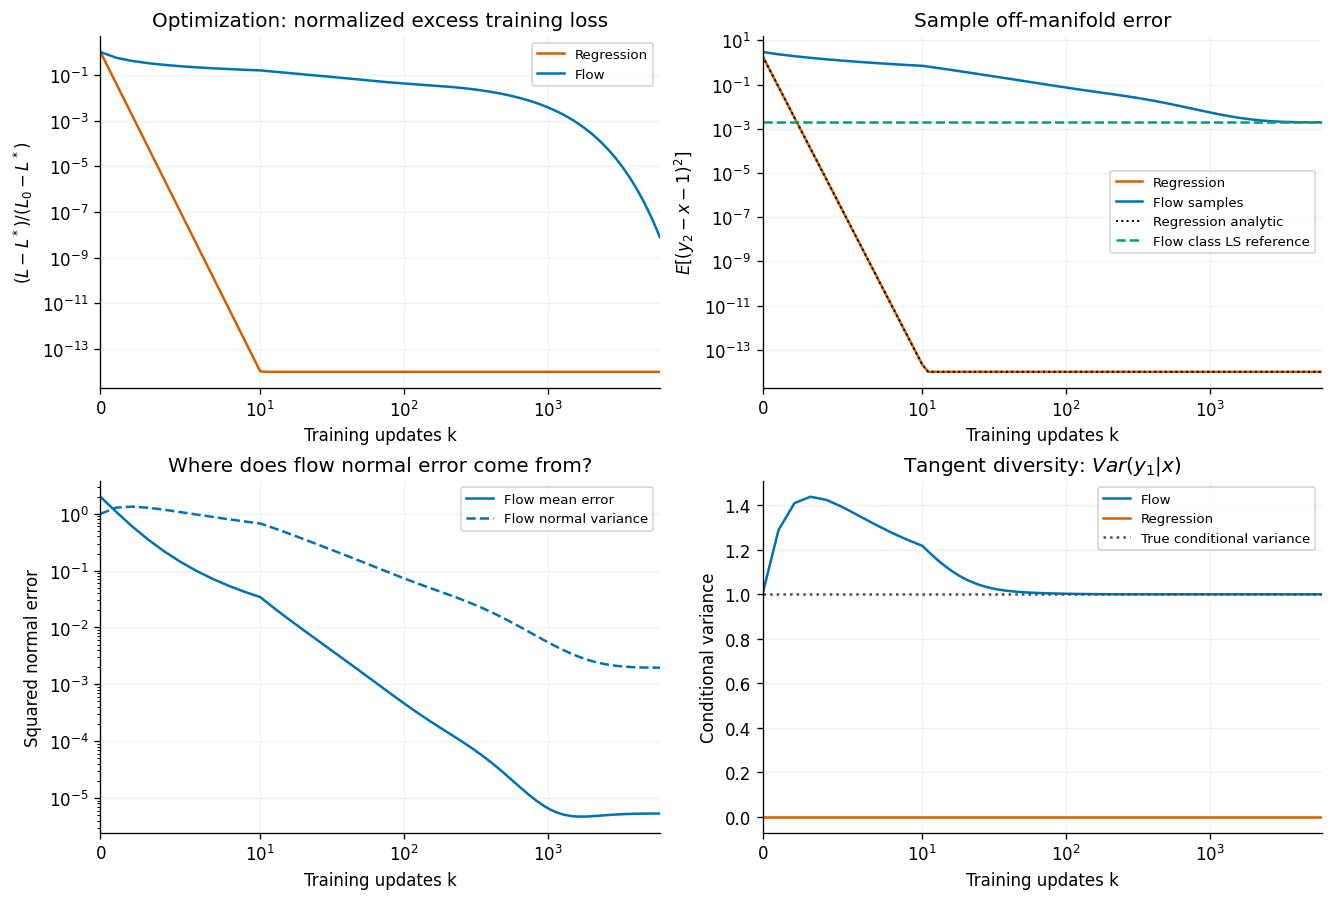

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.4))
floor = 1e-14  # Display floor only; stored metrics are never clipped.
k = np.arange(TRAIN_STEPS + 1)
for losses, optimum, color, label in [
    (reg_losses, float(regression_loss(W_REG_STAR)), REG, "Regression"),
    (flow_losses, float(flow_loss(THETA_STAR)), FLOW, "Flow"),
]:
    gap = (losses - optimum) / (losses[0] - optimum)
    axes[0, 0].plot(k, np.maximum(gap, floor), color=color, label=label)
axes[0, 0].set(title="Optimization: normalized excess training loss", ylabel="$(L-L^*)/(L_0-L^*)$", yscale="log")
axes[0, 1].plot(CHECKPOINTS, np.maximum(reg_metrics[:, 0], floor), color=REG, label="Regression")
axes[0, 1].plot(CHECKPOINTS, flow_metrics[:, 0], color=FLOW, label="Flow samples")
analytic_reg = 2 * (1 - ETA_REG) ** (2 * CHECKPOINTS)
axes[0, 1].plot(CHECKPOINTS, np.maximum(analytic_reg, floor), "k:", lw=1.2, label="Regression analytic")
axes[0, 1].axhline(star_metrics[0], color=ORACLE, ls="--", label="Flow class LS reference")
axes[0, 1].set(title="Sample off-manifold error", ylabel="$E[(y_2-x-1)^2]$", yscale="log")
axes[1, 0].plot(CHECKPOINTS, np.maximum(flow_metrics[:, 1], floor), color=FLOW, label="Flow mean error")
axes[1, 0].plot(CHECKPOINTS, np.maximum(flow_metrics[:, 2], floor), color=FLOW, ls="--", label="Flow normal variance")
axes[1, 0].set(title="Where does flow normal error come from?", ylabel="Squared normal error", yscale="log")
axes[1, 1].plot(CHECKPOINTS, flow_metrics[:, 3], color=FLOW, label="Flow")
axes[1, 1].plot(CHECKPOINTS, reg_metrics[:, 3], color=REG, label="Regression")
axes[1, 1].axhline(1, color="0.3", ls=":", label="True conditional variance")
axes[1, 1].set(title="Tangent diversity: $Var(y_1|x)$", ylabel="Conditional variance")
for ax in axes.flat:
    ax.set_xscale("symlog", linthresh=10)
    ax.set_xlim(0, TRAIN_STEPS)
    ax.set_xlabel("Training updates k")
    ax.legend(fontsize=8)
plt.show()

## 5. Inspect generated samples during training

固定同一个 $x$ 和同一组初始噪声，避免把不同随机抽样误认为训练变化。灰色样本来自真实 conditional distribution，红星是 regression 输出，蓝点是 flow 生成样本。图中直线仅用于评估/展示，不参与采样。

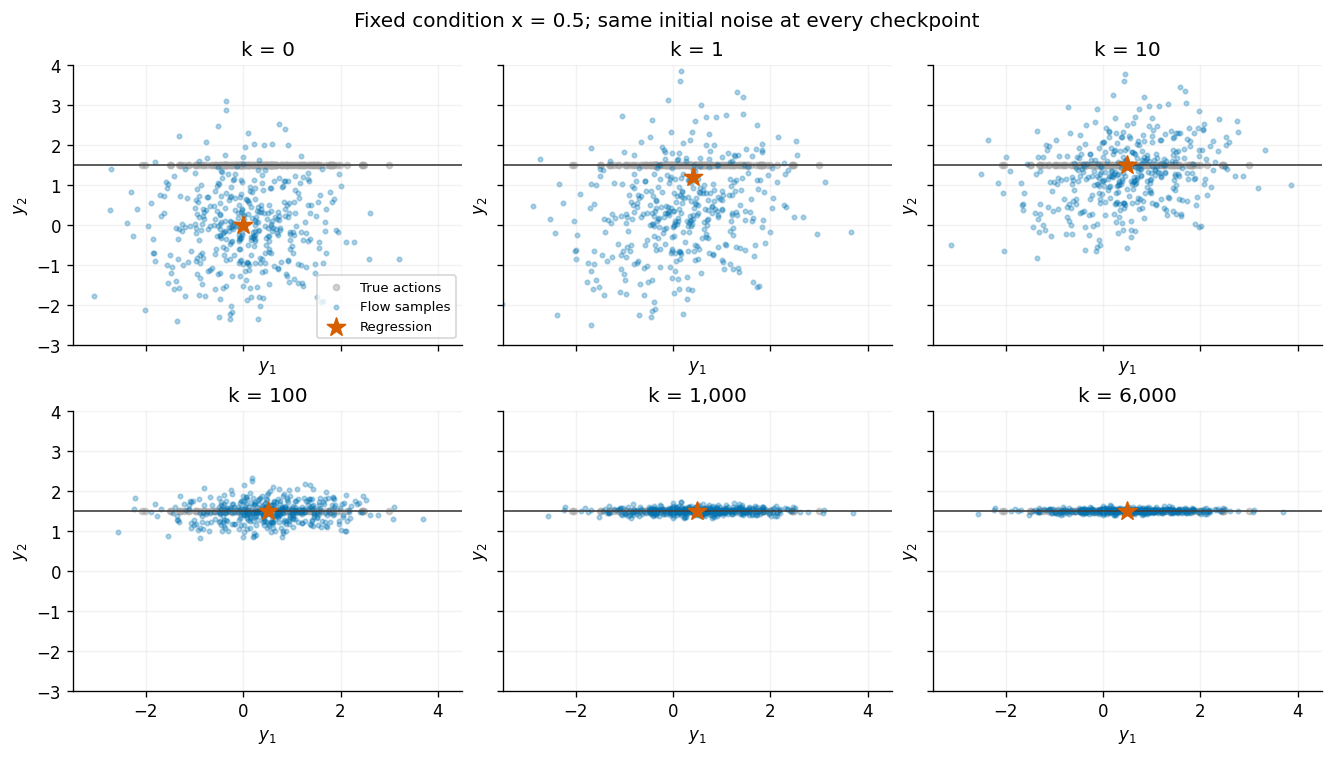

In [7]:
SNAPSHOTS = np.unique(np.clip([0, 1, 10, 100, 1000, TRAIN_STEPS], 0, TRAIN_STEPS))
noise = np.asarray(jax.random.normal(jax.random.key(SEED + 2), (400, 2)))
inputs = np.column_stack([noise, np.full(len(noise), X_INSPECT), np.ones(len(noise))])
truth = np.column_stack([X_INSPECT + z_show, np.full_like(z_show, X_INSPECT + 1)])
snapshot_maps = np.asarray(jax.vmap(lambda theta: flow_path(theta)[-1])(flow_history[SNAPSHOTS]))
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), sharex=True, sharey=True)
for ax, step, matrix in zip(axes.flat, SNAPSHOTS, snapshot_maps):
    generated = inputs @ matrix.T
    reg = np.asarray(reg_history[step]) @ np.array([X_INSPECT, 1.])
    ax.axhline(X_INSPECT + 1, color="0.25", lw=1)
    ax.scatter(*truth.T, color="0.65", s=13, alpha=0.5, label="True actions")
    ax.scatter(*generated.T, color=FLOW, s=7, alpha=0.3, label="Flow samples")
    ax.scatter(*reg, color=REG, marker="*", s=130, zorder=5, label="Regression")
    ax.set(title=f"k = {step:,}", xlim=(-3.5, 4.5), ylim=(-3, 4), xlabel="$y_1$", ylabel="$y_2$")
for ax in axes.flat[len(SNAPSHOTS):]:
    ax.set_visible(False)
axes.flat[0].legend(fontsize=8, loc="lower right")
fig.suptitle(f"Fixed condition x = {X_INSPECT:g}; same initial noise at every checkpoint")
plt.show()

## 6. Inspect velocity learning and the generation trajectory

左图检查各个 $t$ 上的法向 velocity training error，依然对高斯变量精确求期望。右图检查“离 manifold 一单位”的 action：真实场满足 $(1-t)v_2^*=-1$。越接近终点，有限时间基函数与奇异场的差别越明显。

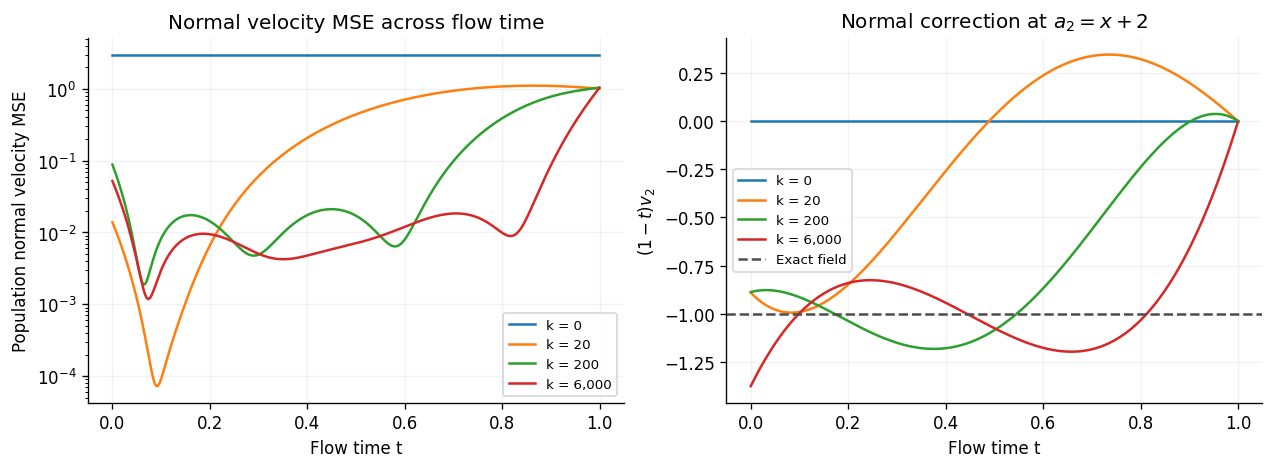

In [8]:
t_inspect = jnp.linspace(0, 0.999, 300)
interp = (1 - t_inspect[:, None, None]) * EPS_MAP + t_inspect[:, None, None] * Y_MAP
inspect_features = jnp.concatenate([interp, jnp.broadcast_to(REG_FEATURES, (len(t_inspect), 2, 5))], axis=1)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
probe = jnp.array([X_INSPECT, X_INSPECT + 2, X_INSPECT, 1.])
for step in np.unique(np.clip([0, 20, 200, TRAIN_STEPS], 0, TRAIN_STEPS)):
    w_t = velocity_weights(flow_history[step], t_inspect)
    residual_map = jnp.einsum("tdf,tfl->tdl", w_t, inspect_features) - V_MAP
    normal_loss_t = np.asarray(jnp.sum(residual_map[:, 1] ** 2, axis=-1))
    axes[0].plot(t_inspect, np.maximum(normal_loss_t, 1e-14), label=f"k = {step:,}")
    normal_velocity = jnp.einsum("tf,f->t", w_t[:, 1], probe)
    axes[1].plot(t_inspect, (1 - t_inspect) * normal_velocity, label=f"k = {step:,}")
axes[0].set(title="Normal velocity MSE across flow time", xlabel="Flow time t", ylabel="Population normal velocity MSE", yscale="log")
axes[1].axhline(-1, color="0.3", ls="--", label="Exact field")
axes[1].set(title="Normal correction at $a_2=x+2$", xlabel="Flow time t", ylabel="$(1-t)v_2$")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

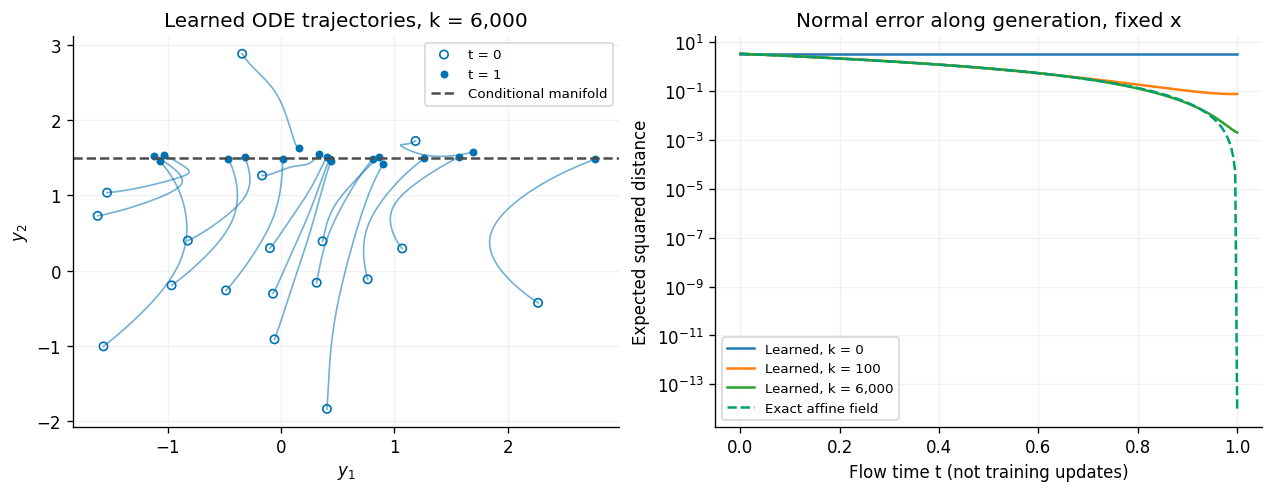

In [9]:
final_path = np.asarray(flow_path(flow_history[-1]))
times = np.linspace(0, 1, ODE_STEPS + 1)
trajectories = np.einsum("tdf,nf->tnd", final_path, inputs[:18])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
for trajectory in trajectories.transpose(1, 0, 2):
    axes[0].plot(*trajectory.T, lw=1, alpha=0.55, color=FLOW)
axes[0].scatter(*trajectories[0].T, facecolors="none", edgecolors=FLOW, s=25, label="t = 0")
axes[0].scatter(*trajectories[-1].T, color=FLOW, s=14, label="t = 1")
axes[0].axhline(X_INSPECT + 1, color="0.3", ls="--", label="Conditional manifold")
axes[0].set(title=f"Learned ODE trajectories, k = {TRAIN_STEPS:,}", xlabel="$y_1$", ylabel="$y_2$")
for step in np.unique(np.clip([0, 100, TRAIN_STEPS], 0, TRAIN_STEPS)):
    path = np.asarray(flow_path(flow_history[step]))
    mean_error = path[:, 1, 2] * X_INSPECT + path[:, 1, 3] - X_INSPECT - 1
    error = np.sum(path[:, 1, :2] ** 2, axis=-1) + mean_error ** 2
    axes[1].plot(times, error, label=f"Learned, k = {step:,}")
oracle_error = (1 - times) ** 2 * (1 + (X_INSPECT + 1) ** 2)
axes[1].plot(times, np.maximum(oracle_error, 1e-14), color=ORACLE, ls="--", label="Exact affine field")
axes[1].set(title="Normal error along generation, fixed x", xlabel="Flow time t (not training updates)", ylabel="Expected squared distance", yscale="log")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

## 7. Numerical checks and experiment readout

检查 regression 是否符合解析训练曲线、Monte Carlo 是否复现 population loss 和 sample metric，以及 RK4 加密后是否改变结论。最后的表格用原始值，不用画图时的 display floor。Flow class LS reference 只用于诊断表示和优化；没有用它替代 GD。

In [10]:
# One compact check of the derivation, training, sampling metric, and solver.
n_check = 50000
k_x, k_eps, k_t = jax.random.split(jax.random.key(SEED + 3), 3)
x_mc, y_mc = sample_data(k_x, n_check)
eps_mc = jax.random.normal(k_eps, (n_check, 2))
t_mc = jax.random.uniform(k_t, (n_check,))
a_mc = (1 - t_mc[:, None]) * eps_mc + t_mc[:, None] * y_mc
phi_mc = jnp.column_stack([a_mc, x_mc, jnp.ones(n_check)])
pred_v = jnp.einsum("ndf,nf->nd", velocity_weights(flow_history[-1], t_mc), phi_mc)
mc_loss = float(0.5 * jnp.mean(jnp.sum((pred_v - (y_mc - eps_mc)) ** 2, axis=1)))
mc_inputs = jnp.column_stack([eps_mc, x_mc, jnp.ones(n_check)])
mc_actions = mc_inputs @ flow_maps[-1].T
mc_off = float(jnp.mean((mc_actions[:, 1] - x_mc - 1) ** 2))
refined_map = flow_path(flow_history[-1], n_steps=2 * ODE_STEPS)[-1]
solver_change = float(jnp.max(jnp.abs(refined_map - flow_maps[-1])))
np.testing.assert_allclose(reg_metrics[:, 0], analytic_reg, atol=1e-13, rtol=1e-9)
np.testing.assert_allclose(flow_path(jnp.zeros_like(THETA_STAR))[-1], jnp.eye(4)[:2], atol=1e-13)
assert abs(mc_loss - flow_losses[-1]) < 0.04, "Population loss disagrees with sampled CFM."
assert np.isclose(mc_off, flow_metrics[-1, 0], rtol=0.08, atol=1e-6), "Sample metric disagrees with exact moments."
assert solver_change < 1e-5, "Increase ODE_STEPS before interpreting training curves."
assert np.isfinite(flow_metrics).all() and np.isfinite(flow_losses).all()
print(f"All checks passed. CFM loss: exact {flow_losses[-1]:.6f}, Monte Carlo {mc_loss:.6f}")
print(f"Flow off-manifold: exact {flow_metrics[-1, 0]:.6g}, Monte Carlo {mc_off:.6g}")
print(f"RK4 refinement: largest endpoint-coefficient change = {solver_change:.2e}")

rows = [
    ("Regression, final", reg_metrics[-1], reg_losses[-1]),
    ("Flow, final GD", flow_metrics[-1], flow_losses[-1]),
    ("Flow, class LS reference", star_metrics, float(flow_loss(THETA_STAR))),
]
table = "| Model | Off-manifold MSE | Normal mean error | Normal variance | Tangent variance | Own training loss |\n"
table += "|---|---:|---:|---:|---:|---:|\n"
for name, values, loss in rows:
    table += f"| {name} | " + " | ".join(f"{value:.6g}" for value in values) + f" | {loss:.6g} |\n"
display(Markdown(table))
reg_reduction = reg_metrics[-1, 0] / reg_metrics[0, 0]
flow_reduction = flow_metrics[-1, 0] / flow_metrics[0, 0]
display(Markdown(
    f"**当前配置的结果。** Regression 的相对法向误差为 `{reg_reduction:.3g}`，"
    f"flow 为 `{flow_reduction:.3g}`。Flow 最终 loss 与本模型类最优 loss 的差为 "
    f"`{flow_losses[-1] - float(flow_loss(THETA_STAR)):.3g}`。这些值描述本 notebook 的模型和训练协议。"
))

All checks passed. CFM loss: exact 0.812145, Monte Carlo 0.810861
Flow off-manifold: exact 0.00196457, Monte Carlo 0.00197589
RK4 refinement: largest endpoint-coefficient change = 4.34e-10


| Model | Off-manifold MSE | Normal mean error | Normal variance | Tangent variance | Own training loss |
|---|---:|---:|---:|---:|---:|
| Regression, final | 0 | 0 | 0 | 0 | 0.5 |
| Flow, final GD | 0.00196457 | 5.31839e-06 | 0.00195926 | 0.999904 | 0.812145 |
| Flow, class LS reference | 0.00196168 | 5.32294e-06 | 0.00195635 | 0.999904 | 0.812145 |


**当前配置的结果。** Regression 的相对法向误差为 `0`，flow 为 `0.000655`。Flow 最终 loss 与本模型类最优 loss 的差为 `1.69e-08`。这些值描述本 notebook 的模型和训练协议。

## How to interpret and extend this inspection

- **Regression 是很强的基准。** 法向标签无噪声且模型正确指定；这里应复现解析的几何收敛。令 `STEP_FRACTION = 1.0` 可检查 regression 的 population 一步收敛。
- **Flow 优化与 adherence 是两个量。** Training loss 接近 class LS optimum 后仍有法向生成误差，不应继续归因于“训练步数不够”。同时，最小 velocity loss 不保证最小 off-manifold error。
- **法向方差与均值要分开看。** Flow 的均值可能已接近 manifold，但样本仍有法向厚度；regression 没有条件采样方差。
- **改变 `DEGREE` 是表示/conditioning 的消融。** 更高阶可能减小终点表示误差，也可能使 GD 更慢。比较时同时看 class LS reference、训练 loss gap 和 Hessian condition number，不能只看最终误差。
- **先固定时间表示再比较训练率。** 对更新步数的结论不等于计算效率结论；当前初始化的初始输出误差也不同。若做公平性更强的研究，还需明确相同输出初始化、预算和学习率选择规则。

可优先尝试 `DEGREE = 1, 3, 5`、`STEP_FRACTION = 0.2, 0.8, 1.0`，或仅增加 `TRAIN_STEPS`。默认结果用于建立可解释基准；它不构成 flow 在一般非线性 manifold 上优劣的结论。

References: [Flow Matching for Generative Modeling](https://arxiv.org/abs/2210.02747), [JAX random keys](https://docs.jax.dev/en/latest/random-numbers.html), [JAX scan](https://docs.jax.dev/en/latest/_autosummary/jax.lax.scan.html).

## Part 1 — nonlinear $\mu(x)$, without changing conditional manifold geometry

现在只改变条件均值：
$$\mu_\omega(x)=\begin{pmatrix}x\\1+x+\sin(\omega x)\end{pmatrix},\qquad
Y=\mu_\omega(X)+\begin{pmatrix}Z\\0\end{pmatrix},\quad X,Z\overset{\mathrm{iid}}\sim\mathcal N(0,1).$$
预先固定 $\omega\in\{0,1,3,6\}$；$\omega=0$ 复现原始数据，随后逐渐增加条件映射的频率。给定 $x$ 的 action manifold 仍然是水平直线：
$$\mathcal M_x=\{(s,\mu_{\omega,2}(x)):s\in\mathbb R\},\qquad
\mathcal E=\mathbb E[(\widehat Y_2-\mu_{\omega,2}(X))^2].$$
这一步增加的是 **条件均值的非线性**，并没有引入弯曲的条件 action manifold、多模态或法向标签噪声。

按以下顺序区分三个问题：
1. 仍用 affine regression 时，能达到的最好误差是多少？
2. 若直接提供正确的非线性基函数，regression 是否仍能一步收敛？
3. 两边都必须学习条件表示后，行为是否开始分化？

In [11]:
import time
from jax.example_libraries import optimizers

NN_WIDTH = 16
NN_STEPS = 12000
NN_LEARNING_RATES = np.array([0.001, 0.003])
PRIMARY_LR_INDEX = 1
NN_SEEDS = np.arange(5)
FREQUENCIES = np.array([0., 1., 3., 6.])
NN_OMEGAS = jnp.asarray(np.repeat(FREQUENCIES, len(NN_SEEDS)))
NN_RUN_SEEDS = jnp.asarray(np.tile(NN_SEEDS, len(FREQUENCIES)))
NN_CHECKPOINTS = np.unique(np.r_[0, 1, 10, 100, np.geomspace(200, NN_STEPS, 60).astype(int)])


def gaussian_quadrature(n):
    nodes, weights = np.polynomial.hermite.hermgauss(n)
    return jnp.asarray(np.sqrt(2) * nodes), jnp.asarray(weights / np.sqrt(np.pi))


def dense_normal_quadrature(n):
    nodes, weights = np.polynomial.legendre.leggauss(n)
    x = 6 * nodes
    weights = 6 * weights * np.exp(-x ** 2 / 2) / np.sqrt(2 * np.pi)
    return jnp.asarray(x), jnp.asarray(weights / weights.sum())


def nonlinear_mean(x, omega):
    return jnp.stack([x, 1 + x + jnp.sin(omega * x)], axis=-1)


NN_X, NN_XW = dense_normal_quadrature(512)
NN_X_TEST, NN_XW_TEST = dense_normal_quadrature(1024)
NN_MU = jax.vmap(lambda omega: nonlinear_mean(NN_X, omega))(NN_OMEGAS)

### Matched trainable condition encoders

两边分别学习同结构的两层、宽度 16 的 tanh encoder：
$$\phi_\psi(x)=[x,h_\psi(x),1]^\top\in\mathbb R^{18}.$$
每个 seed 内 encoder 初始化相同，之后各自训练，不共享更新。
$$f_R(x)=R\phi_{\psi_R}(x),\qquad
v_F(a,t,x)=K_\Theta(t)a+G_\Theta(t)\phi_{\psi_F}(x).$$
$K,G$ 沿用三阶 Legendre 时间基函数。Flow 对 action 仍是 affine，对 $x$ 可以是非线性；这类结构适合本例的条件 Gaussian 分布。Regression 有 340 个参数，flow 有 464 个参数：匹配了条件 encoder，但总参数数并不相同。

**优化协议。** 本节使用相同 Adam 学习率、相同更新预算的配对比较：5 个初始化 seed，学习率 $0.001,0.003$，每个组合 12,000 步。主图预先选择 $0.003$；表格报告两种学习率，避免只展示有利配置。Part 0 用 GD，本节用 Adam，不把跨 Part 的速度变化归因于某个单独因素。

**Population loss 的数值计算。** 对 $Z,\varepsilon$ 精确求期望。对 $X$ 用 $[-6,6]$ 上 512 节点的 Gaussian 加权积分，对 $t$ 用原来的 Gauss–Legendre 积分；区间外 Gaussian 概率约 $2\times10^{-9}$。独立 1024/1536 节点及 Monte Carlo 用于检查数值网格偏差。

直接把 flow-matching loss 对数据噪声和初始噪声积分，可得到下面实现的式子，其中 $B=(1,0)^\top$：
$$\mathcal L_F=\tfrac12\mathbb E_{X,t}\|tK_t\mu(X)+G_t\phi(X)-\mu(X)\|^2
+\tfrac12\mathbb E_t\left[\|tK_tB-B\|^2+\|(1-t)K_t+I\|_F^2\right].$$
三个部分分别对应条件平均速度残差、数据切向噪声系数残差、初始 Gaussian 噪声系数残差。这是原始 CFM objective 的期望，不是用解析最优 velocity 替代训练标签。

In [12]:
def init_nonlinear_models(seed):
    key1, key2 = jax.random.split(jax.random.key(seed))
    encoder = ((jax.random.normal(key1, (1, NN_WIDTH)), jnp.zeros(NN_WIDTH)),
               (jax.random.normal(key2, (NN_WIDTH, NN_WIDTH)) / jnp.sqrt(NN_WIDTH), jnp.zeros(NN_WIDTH)))
    reg = {"encoder": encoder, "head": jnp.zeros((2, NN_WIDTH + 2))}
    flow = {"encoder": encoder, "head": jnp.zeros((DEGREE + 1, 2, NN_WIDTH + 4))}
    return reg, flow


def condition_features(encoder, x):
    h = x[:, None]
    for w, b in encoder:
        h = jnp.tanh(h @ w + b)
    return jnp.column_stack([x, h, jnp.ones_like(x)])


def nonlinear_losses(pair, means, x=NN_X, x_weights=NN_XW):
    reg, flow = pair
    phi_reg = condition_features(reg["encoder"], x)
    phi_flow = condition_features(flow["encoder"], x)
    reg_residual = phi_reg @ reg["head"].T - means
    loss_reg = 0.5 * jnp.sum(x_weights[:, None] * reg_residual ** 2) + 0.5

    weights_t = jnp.einsum("qj,jdf->qdf", time_basis(T_QUAD), flow["head"])
    k_t, g_t = weights_t[:, :, :2], weights_t[:, :, 2:]
    residual = jnp.einsum("qij,xj->xqi", T_QUAD[:, None, None] * k_t - jnp.eye(2), means)
    residual += jnp.einsum("qif,xf->xqi", g_t, phi_flow)
    z_residual = T_QUAD[:, None] * k_t[:, :, 0] - jnp.array([1., 0.])
    eps_residual = (1 - T_QUAD[:, None, None]) * k_t + jnp.eye(2)
    loss_flow = 0.5 * jnp.sum(x_weights[:, None, None] * T_WEIGHTS[None, :, None] * residual ** 2)
    loss_flow += 0.5 * jnp.sum(T_WEIGHTS * (jnp.sum(z_residual ** 2, axis=1) + jnp.sum(eps_residual ** 2, axis=(1, 2))))
    return jnp.array([loss_reg, loss_flow])


def joint_nonlinear_loss(pair, means):
    return nonlinear_losses(pair, means).sum()

由于 flow 对 action 是 affine，生成结果仍为
$$\widehat Y_F=L\varepsilon+C\phi_{\psi_F}(x).$$
只需积分一个小矩阵，就能获得任意 $x$ 下的条件均值和方差。法向误差精确分解为
$$\mathcal E_F=\mathbb E_X[(C\phi_{\psi_F}(X))_2-\mu_2(X)]^2+\|L_{2,:}\|^2.$$
生成依然使用整个 $[0,1]$ 上的普通 RK4，没有 terminal projection 或 denoising。有限时间多项式的终点表示限制仍然存在。

In [13]:
@partial(jax.jit, static_argnames=("n_steps",))
def nonlinear_flow_path(head, n_steps=128):
    dt = 1 / n_steps
    times = jnp.arange(n_steps) * dt
    w_t = jnp.einsum("qsj,jdf->qsdf", time_basis(times[:, None] + dt * jnp.array([0., 0.5, 1.])), head)
    n_features = head.shape[-1] - 2
    forcing = jnp.column_stack([jnp.zeros((n_features, 2)), jnp.eye(n_features)])

    def rhs(matrix, w):
        return w[:, :2] @ matrix + w[:, 2:] @ forcing

    def step(matrix, weights):
        k1 = rhs(matrix, weights[0])
        k2 = rhs(matrix + dt * k1 / 2, weights[1])
        k3 = rhs(matrix + dt * k2 / 2, weights[1])
        k4 = rhs(matrix + dt * k3, weights[2])
        matrix = matrix + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        return matrix, matrix

    initial = jnp.column_stack([jnp.eye(2), jnp.zeros((2, n_features))])
    _, path = jax.lax.scan(step, initial, w_t)
    return jnp.concatenate([initial[None], path])


def nonlinear_metrics(pair, omega):
    reg, flow = pair
    target = nonlinear_mean(NN_X_TEST, omega)
    pred_reg = condition_features(reg["encoder"], NN_X_TEST) @ reg["head"].T
    matrix = nonlinear_flow_path(flow["head"])[-1]
    pred_flow = condition_features(flow["encoder"], NN_X_TEST) @ matrix[:, 2:].T
    bias_reg = jnp.sum(NN_XW_TEST * (pred_reg[:, 1] - target[:, 1]) ** 2)
    bias_flow = jnp.sum(NN_XW_TEST * (pred_flow[:, 1] - target[:, 1]) ** 2)
    variance_flow = jnp.sum(matrix[1, :2] ** 2)
    return jnp.array([bias_reg, bias_flow + variance_flow, bias_flow,
                      variance_flow, jnp.sum(matrix[0, :2] ** 2)])

### A–B. Affine misspecification and known-feature controls

记 $c_\omega=\omega e^{-\omega^2/2}$，$s_\omega^2=\tfrac12(1-e^{-2\omega^2})-c_\omega^2$。最佳 affine 法向预测是
$$\widehat\mu_{\rm affine,2}(x)=1+(1+c_\omega)x,$$
其不可消除的法向 MSE 正好是 $s_\omega^2$。这是模型欠拟合下限，与训练快慢无关。

对于 $\omega>0$，使用已知特征
$$\phi_*(x)=\left[x,\frac{\sin(\omega x)-c_\omega x}{s_\omega},1\right]^\top$$
后，$\mathbb E[\phi_*\phi_*^\top]=I$。正确指定的 regression 又能在 population GD 的一步中达到零法向误差。这是一个控制实验：**非线性 $\mu(x)$ 本身仍不足以排除一步收敛。**

同时计算这个已知特征空间里的 flow 最小二乘解。它只用于诊断，不参与网络训练，也不是 off-manifold error 的理论下界。

In [14]:
def known_condition_features(x, omega):
    if omega == 0:
        return np.column_stack([x, np.ones_like(x)])
    c = omega * np.exp(-omega ** 2 / 2)
    s = np.sqrt((1 - np.exp(-2 * omega ** 2)) / 2 - c ** 2)
    return np.column_stack([x, (np.sin(omega * x) - c * x) / s, np.ones_like(x)])


control_x, control_w = map(np.asarray, gaussian_quadrature(128))
control_rows, known_flow_heads = [], []
for omega in FREQUENCIES:
    phi = known_condition_features(control_x, float(omega))
    mu = np.asarray(nonlinear_mean(jnp.asarray(control_x), omega))
    one_step_head = np.einsum("x,xd,xf->df", control_w, mu, phi)
    reg_one_step_error = np.sum(control_w * ((phi @ one_step_head.T)[:, 1] - mu[:, 1]) ** 2)

    # Conditional random variables are maps of [z, eps_1, eps_2, 1].
    y_map = np.zeros((len(control_x), 2, 4))
    y_map[:, 0, 0] = 1
    y_map[:, :, -1] = mu
    eps_map = np.eye(4)[1:3]
    a_map = (1 - np.asarray(T_QUAD)[None, :, None, None]) * eps_map
    a_map = a_map + np.asarray(T_QUAD)[None, :, None, None] * y_map[:, None]
    phi_map = np.zeros((len(control_x), len(T_QUAD), phi.shape[1], 4))
    phi_map[:, :, :, -1] = phi[:, None]
    input_map = np.concatenate([a_map, phi_map], axis=2)
    design = (np.asarray(time_basis(T_QUAD))[None, :, :, None, None] * input_map[:, :, None]).reshape(len(control_x), len(T_QUAD), -1, 4)
    hessian = np.einsum("x,t,xtfk,xtgk->fg", control_w, np.asarray(T_WEIGHTS), design, design, optimize=True)
    cross = np.einsum("x,t,xdk,xtfk->df", control_w, np.asarray(T_WEIGHTS), y_map - eps_map, design, optimize=True)
    head = np.linalg.solve(hessian, cross.T).T.reshape(2, DEGREE + 1, -1).transpose(1, 0, 2)
    known_flow_heads.append(head)
    transfer = np.asarray(nonlinear_flow_path(jnp.asarray(head))[-1])
    mean_flow = phi @ transfer[:, 2:].T
    flow_reference = np.sum(control_w * (mean_flow[:, 1] - mu[:, 1]) ** 2) + np.sum(transfer[1, :2] ** 2)
    c = omega * np.exp(-omega ** 2 / 2)
    affine_floor = (1 - np.exp(-2 * omega ** 2)) / 2 - c ** 2
    control_rows.append([omega, affine_floor, reg_one_step_error, flow_reference])
control_rows = np.asarray(control_rows)
assert np.max(control_rows[:, 2]) < 1e-12
np.testing.assert_allclose(control_rows[0, 3], star_metrics[0], rtol=1e-5)
control_table = "| Frequency | Best affine normal MSE | Known-feature regression: one step | Known-feature flow LS reference |\n|---|---:|---:|---:|\n"
for row in control_rows:
    control_table += "| " + " | ".join(f"{value:.6g}" for value in row) + " |\n"
display(Markdown(control_table))

| Frequency | Best affine normal MSE | Known-feature regression: one step | Known-feature flow LS reference |
|---|---:|---:|---:|
| 0 | 0 | 1.15163e-31 | 0.00196168 |
| 1 | 0.0644529 | 3.56048e-31 | 0.00221578 |
| 3 | 0.498889 | 1.54946e-31 | 0.00207378 |
| 6 | 0.5 | 7.00587e-32 | 0.00206278 |


### C. Learn the nonlinear condition representation

零 head 初始化：regression 的输出和 flow 的条件生成均值都从 0 开始；flow 初始仍有法向噪声方差 1。下面绘制原始 sample off-manifold MSE，并把 flow 的均值误差单独列出。训练参数只在固定 checkpoint 保存；没有挑选 best checkpoint。

CPU 下本节会比 Part 0 更慢。每种学习率都完整运行 20 组配对实验；总计 40 组配对、80 个模型。

In [15]:
initial_nonlinear_params = jax.vmap(init_nonlinear_models)(NN_RUN_SEEDS)
nn_opt_init, _, nn_get_params = optimizers.adam(1.)


@jax.jit
def advance_nonlinear(state, start, stop, learning_rate):
    opt_update = optimizers.adam(learning_rate)[1]
    def step(i, state):
        params = nn_get_params(state)
        grads = jax.vmap(jax.grad(joint_nonlinear_loss))(params, NN_MU)
        return opt_update(i, grads, state)
    return jax.lax.fori_loop(start, stop, step, state)


nn_started = time.perf_counter()
nn_histories = []
for learning_rate in NN_LEARNING_RATES:
    nn_state = nn_opt_init(initial_nonlinear_params)
    nn_saved = [initial_nonlinear_params]
    for start, stop in zip(NN_CHECKPOINTS[:-1], NN_CHECKPOINTS[1:]):
        nn_state = advance_nonlinear(nn_state, int(start), int(stop), float(learning_rate))
        params = nn_get_params(nn_state)
        jax.block_until_ready(params)
        nn_saved.append(params)
        if stop in NN_CHECKPOINTS[::15] or stop == NN_STEPS:
            print(f"lr={learning_rate:g}, updates {stop:>5,}/{NN_STEPS:,}, elapsed {time.perf_counter()-nn_started:.1f}s", flush=True)
    nn_histories.append(jax.tree.map(lambda *arrays: jnp.stack(arrays), *nn_saved))
nn_history = jax.tree.map(lambda *arrays: jnp.stack(arrays), *nn_histories)
nn_final = jax.tree.map(lambda arrays: arrays[:, -1], nn_history)
print(f"Completed {len(NN_OMEGAS)*len(NN_LEARNING_RATES)} paired runs in {time.perf_counter()-nn_started:.1f}s.")

lr=0.001, updates   429/12,000, elapsed 4.2s
lr=0.001, updates 1,215/12,000, elapsed 10.0s
lr=0.001, updates 3,441/12,000, elapsed 30.1s
lr=0.001, updates 9,744/12,000, elapsed 79.5s
lr=0.001, updates 12,000/12,000, elapsed 98.7s
lr=0.003, updates   429/12,000, elapsed 102.2s
lr=0.003, updates 1,215/12,000, elapsed 113.3s
lr=0.003, updates 3,441/12,000, elapsed 135.9s
lr=0.003, updates 9,744/12,000, elapsed 189.2s
lr=0.003, updates 12,000/12,000, elapsed 209.2s
Completed 40 paired runs in 211.4s.


In [16]:
evaluate_history = jax.jit(jax.vmap(jax.vmap(nonlinear_metrics, in_axes=(0, 0)), in_axes=(0, None)))
evaluate_losses = jax.jit(jax.vmap(jax.vmap(nonlinear_losses, in_axes=(0, 0))))
nn_metrics = np.stack([np.asarray(evaluate_history(history, NN_OMEGAS)) for history in nn_histories])
all_means = jnp.broadcast_to(NN_MU, (len(NN_CHECKPOINTS),) + NN_MU.shape)
nn_loss_history = np.stack([np.asarray(evaluate_losses(history, all_means)) for history in nn_histories])
print("Metrics: regression off-MSE, flow off-MSE, flow bias, flow variance, tangent variance")
print(nn_metrics[:, -1].reshape(len(NN_LEARNING_RATES), len(FREQUENCIES), len(NN_SEEDS), -1).mean(axis=2))

Metrics: regression off-MSE, flow off-MSE, flow bias, flow variance, tangent variance
[[[1.55023995e-06 1.96371636e-03 4.99132700e-06 1.95872503e-03
   9.99957397e-01]
  [6.04177593e-06 2.22755832e-03 1.07908177e-05 2.21676750e-03
   9.99838998e-01]
  [3.04863274e-04 2.43204928e-03 2.33890460e-04 2.19815882e-03
   9.99910210e-01]
  [1.32809019e-03 5.28497208e-03 1.98703147e-03 3.29794061e-03
   9.99958859e-01]]

 [[4.90820785e-06 1.96662286e-03 8.51561806e-06 1.95810724e-03
   9.99913407e-01]
  [6.48887818e-06 2.22550673e-03 9.35914031e-06 2.21614759e-03
   9.99805740e-01]
  [2.56686037e-04 2.36723811e-03 2.08094619e-04 2.15914349e-03
   9.99962637e-01]
  [1.06084526e-03 3.68284249e-03 9.90650205e-04 2.69219229e-03
   9.99903146e-01]]]


### Training inspection: increasing frequency

主图使用预先指定的学习率 0.003。实线为各 seed 的平均 sample off-manifold MSE，浅色带为 seed 间的最小值到最大值；它不是置信区间。蓝色虚线只统计 flow 的条件均值误差，因此不包含法向生成方差。绿色点线为已知正确非线性特征的 flow 参考。

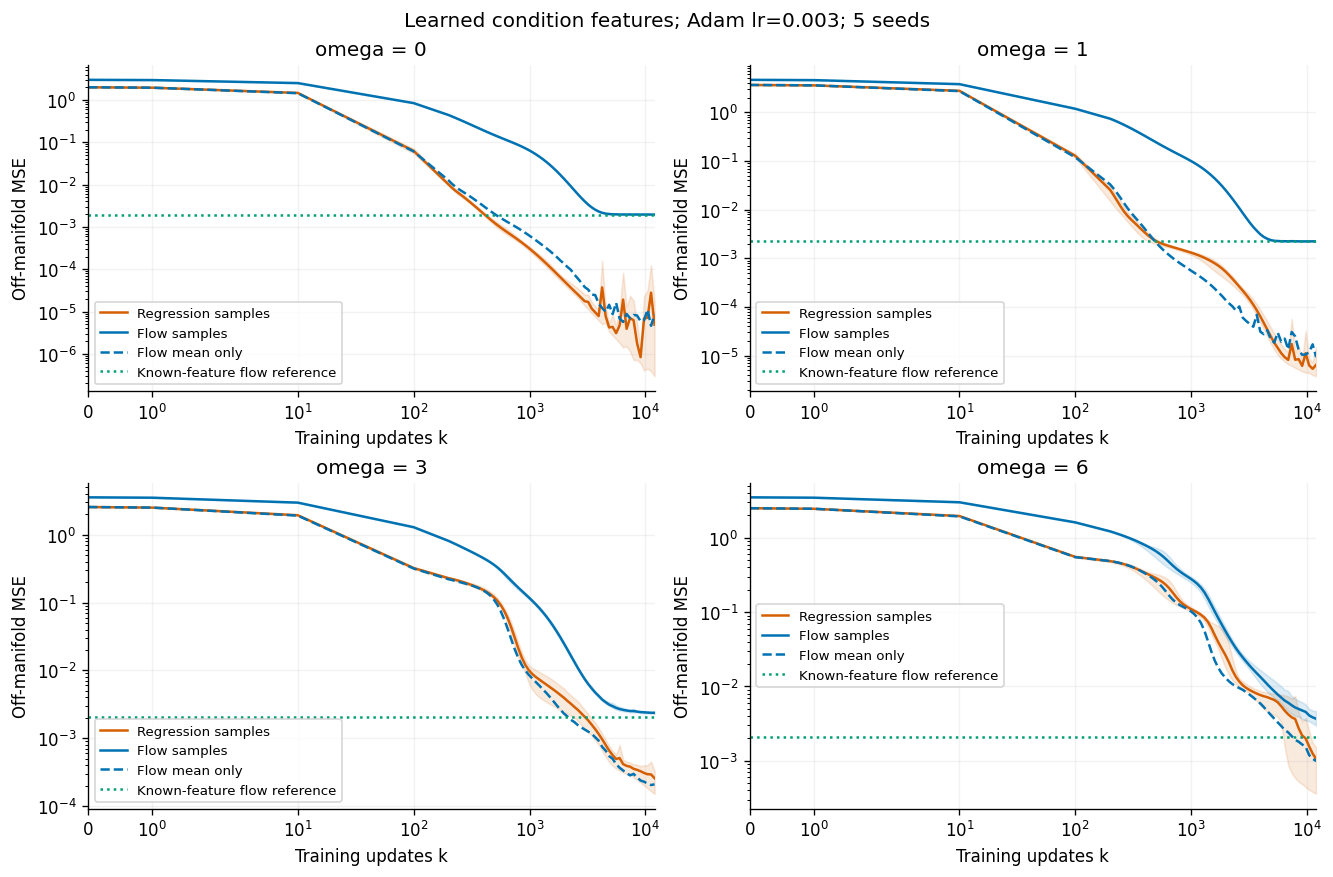

In [17]:
primary_metrics = nn_metrics[PRIMARY_LR_INDEX].reshape(len(NN_CHECKPOINTS), len(FREQUENCIES), len(NN_SEEDS), 5)
fig, axes = plt.subplots(2, 2, figsize=(11, 7.2))
for case, (ax, omega) in enumerate(zip(axes.flat, FREQUENCIES)):
    for metric, color, label in [(0, REG, "Regression samples"), (1, FLOW, "Flow samples")]:
        values = primary_metrics[:, case, :, metric]
        ax.plot(NN_CHECKPOINTS, np.maximum(values.mean(1), 1e-10), color=color, label=label)
        ax.fill_between(NN_CHECKPOINTS, np.maximum(values.min(1), 1e-10), np.maximum(values.max(1), 1e-10), color=color, alpha=0.13)
    ax.plot(NN_CHECKPOINTS, np.maximum(primary_metrics[:, case, :, 2].mean(1), 1e-10), color=FLOW, ls="--", label="Flow mean only")
    ax.axhline(control_rows[case, 3], color=ORACLE, ls=":", label="Known-feature flow reference")
    ax.set(title=f"omega = {omega:g}", xlabel="Training updates k", ylabel="Off-manifold MSE", xscale="symlog", yscale="log", xlim=(0, NN_STEPS))
    ax.legend(fontsize=8)
fig.suptitle(f"Learned condition features; Adam lr={NN_LEARNING_RATES[PRIMARY_LR_INDEX]:g}; {len(NN_SEEDS)} seeds")
plt.show()

### Inspect the learned mean functions

黑线是真实 $\mu_2(x)$；彩色实线是 seed 平均的预测条件均值，带为 seed 的最小值到最大值。所有模型都在完整的 Gaussian 加权条件分布上训练；这里用连续网格展示函数形状。

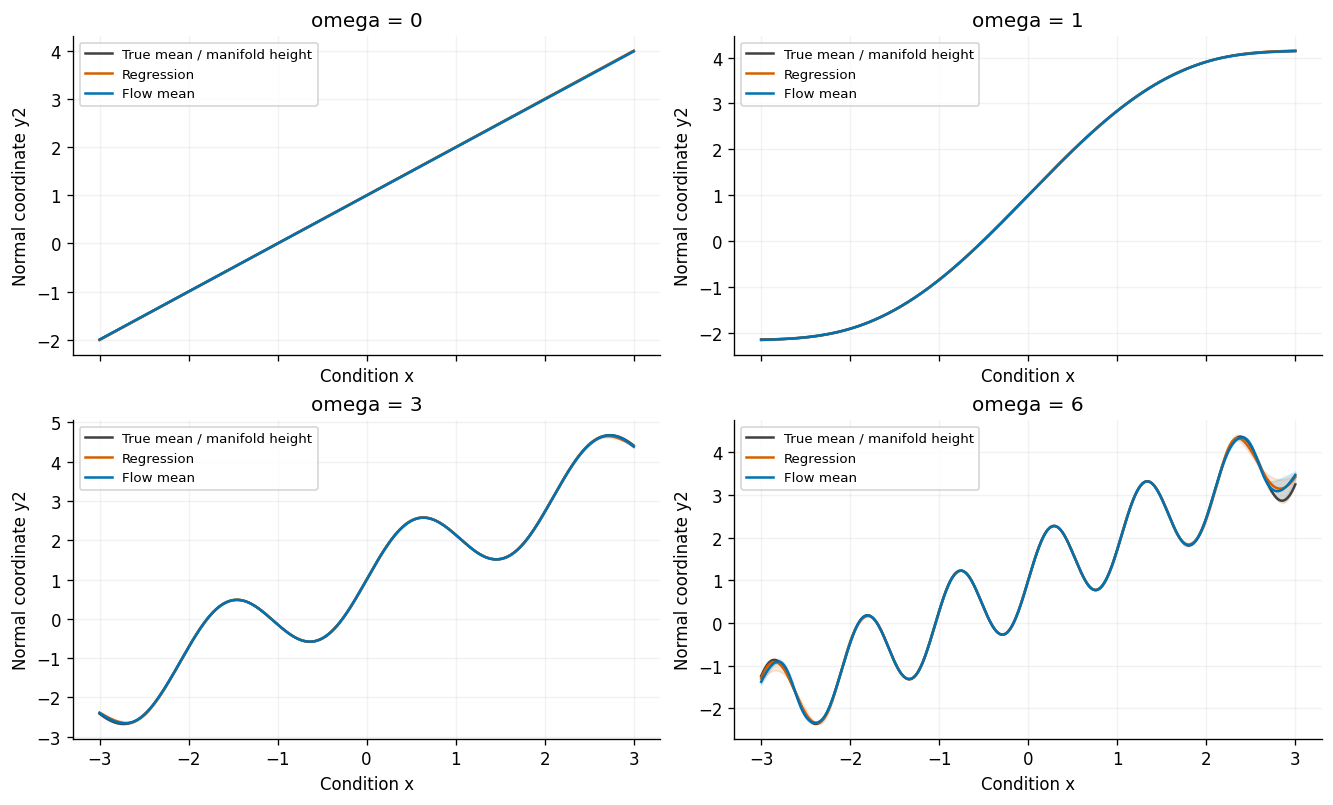

In [18]:
x_plot = jnp.linspace(-3, 3, 700)


def predicted_nonlinear_means(pair, x):
    reg, flow = pair
    pred_r = condition_features(reg["encoder"], x) @ reg["head"].T
    transfer = nonlinear_flow_path(flow["head"])[-1]
    pred_f = condition_features(flow["encoder"], x) @ transfer[:, 2:].T
    return jnp.stack([pred_r, pred_f])


primary_final = jax.tree.map(lambda a: a[PRIMARY_LR_INDEX, -1], nn_history)
grid_predictions = np.asarray(jax.vmap(lambda pair: predicted_nonlinear_means(pair, x_plot))(primary_final))
grid_predictions = grid_predictions.reshape(len(FREQUENCIES), len(NN_SEEDS), 2, len(x_plot), 2)
fig, axes = plt.subplots(2, 2, figsize=(11, 6.6), sharex=True)
for case, (ax, omega) in enumerate(zip(axes.flat, FREQUENCIES)):
    ax.plot(x_plot, nonlinear_mean(x_plot, omega)[:, 1], color="0.25", lw=1.5, label="True mean / manifold height")
    for method, color, label in [(0, REG, "Regression"), (1, FLOW, "Flow mean")]:
        values = grid_predictions[case, :, method, :, 1]
        ax.plot(x_plot, values.mean(0), color=color, label=label)
        ax.fill_between(x_plot, values.min(0), values.max(0), color=color, alpha=0.14)
    ax.set(title=f"omega = {omega:g}", xlabel="Condition x", ylabel="Normal coordinate y2")
    ax.legend(fontsize=8)
plt.show()

### High-frequency case: fitting and normal variance

下面单独查看最高频率的训练过程。左图分别显示各自训练 objective，不把不同 objective 的绝对数值当作公平的预测质量比较。右图把生成误差分解成条件均值误差和法向方差。

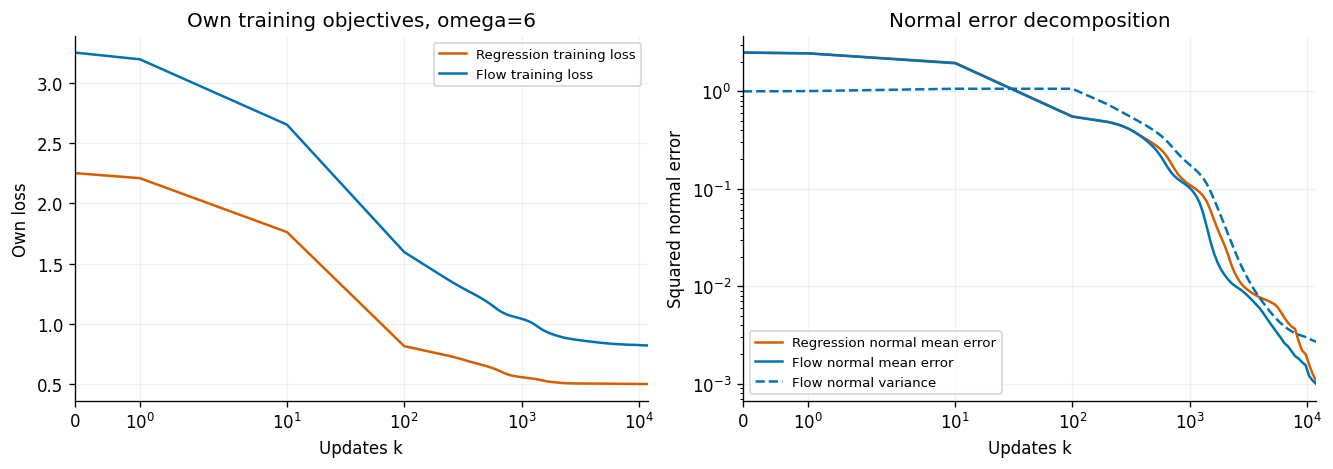

In [19]:
primary_losses = nn_loss_history[PRIMARY_LR_INDEX].reshape(len(NN_CHECKPOINTS), len(FREQUENCIES), len(NN_SEEDS), 2)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(NN_CHECKPOINTS, primary_losses[:, -1, :, 0].mean(1), color=REG, label="Regression training loss")
axes[0].plot(NN_CHECKPOINTS, primary_losses[:, -1, :, 1].mean(1), color=FLOW, label="Flow training loss")
axes[0].set(title=f"Own training objectives, omega={FREQUENCIES[-1]:g}", xlabel="Updates k", ylabel="Own loss", xscale="symlog", xlim=(0, NN_STEPS))
for metric, color, style, label in [(0, REG, "-", "Regression normal mean error"),
    (2, FLOW, "-", "Flow normal mean error"), (3, FLOW, "--", "Flow normal variance")]:
    values = primary_metrics[:, -1, :, metric]
    axes[1].plot(NN_CHECKPOINTS, np.maximum(values.mean(1), 1e-12), color=color, ls=style, label=label)
axes[1].set(title="Normal error decomposition", xlabel="Updates k", ylabel="Squared normal error", xscale="symlog", yscale="log", xlim=(0, NN_STEPS))
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

### Inspect generated actions and their ODE paths

固定最高频率、seed 0、$x=0.5$，不选择最有利的 seed。灰线是真实条件 manifold，红星为 regression 输出。初始噪声是生成的起点，没有额外给 action 添加扰动。右图比较相同 $x$ 下的最终法向 residual 分布。

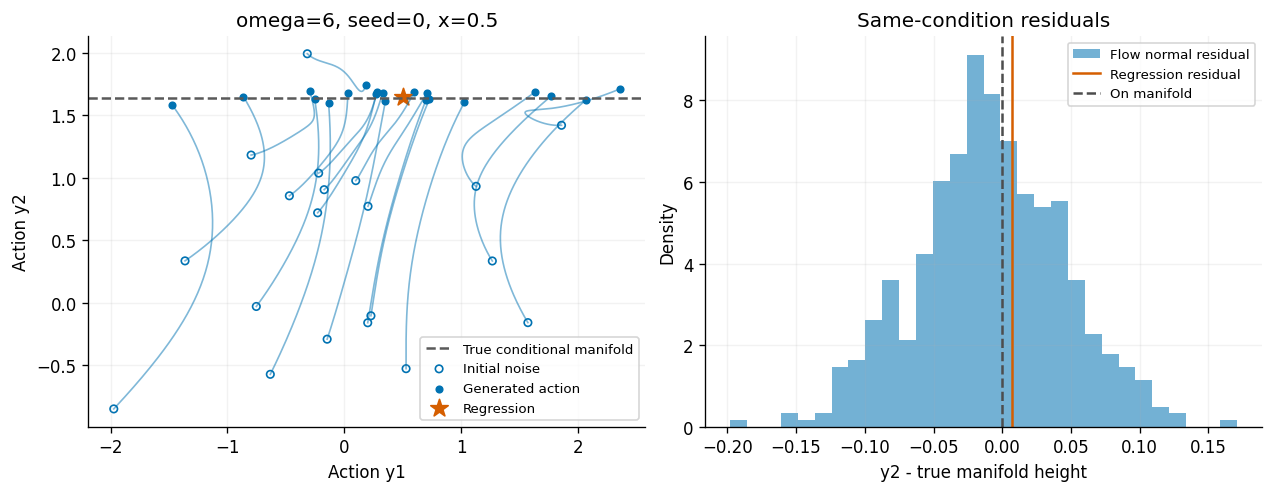

In [20]:
inspect_run = (len(FREQUENCIES) - 1) * len(NN_SEEDS)
inspect_pair = jax.tree.map(lambda a: a[inspect_run], primary_final)
inspect_mu = np.asarray(nonlinear_mean(jnp.array([X_INSPECT]), FREQUENCIES[-1]))[0]
inspect_features = np.asarray(condition_features(inspect_pair[1]["encoder"], jnp.array([X_INSPECT])))[0]
inspect_noise = np.asarray(jax.random.normal(jax.random.key(123), (500, 2)))
inspect_inputs = np.column_stack([inspect_noise, np.broadcast_to(inspect_features, (len(inspect_noise), len(inspect_features)))])
inspect_path = np.asarray(nonlinear_flow_path(inspect_pair[1]["head"]))
inspect_actions = inspect_inputs @ inspect_path[-1].T
inspect_reg = np.asarray(predicted_nonlinear_means(inspect_pair, jnp.array([X_INSPECT])))[0, 0]
paths = np.einsum("tdf,nf->tnd", inspect_path, inspect_inputs[:20])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
for trajectory in paths.transpose(1, 0, 2):
    axes[0].plot(*trajectory.T, color=FLOW, lw=1, alpha=0.5)
axes[0].axhline(inspect_mu[1], color="0.35", ls="--", label="True conditional manifold")
axes[0].scatter(*paths[0].T, facecolors="none", edgecolors=FLOW, s=20, label="Initial noise")
axes[0].scatter(*paths[-1].T, color=FLOW, s=15, label="Generated action")
axes[0].scatter(*inspect_reg, color=REG, marker="*", s=120, label="Regression")
axes[0].set(title=f"omega={FREQUENCIES[-1]:g}, seed=0, x={X_INSPECT:g}", xlabel="Action y1", ylabel="Action y2")
normal_residuals = inspect_actions[:, 1] - inspect_mu[1]
axes[1].hist(normal_residuals, bins=30, density=True, color=FLOW, alpha=0.55, label="Flow normal residual")
axes[1].axvline(inspect_reg[1] - inspect_mu[1], color=REG, label="Regression residual")
axes[1].axvline(0, color="0.3", ls="--", label="On manifold")
axes[1].set(title="Same-condition residuals", xlabel="y2 - true manifold height", ylabel="Density")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

### Full fixed-budget results and learning-rate sensitivity

以下全部使用最后一步，而非最优 checkpoint。$\pm$ 表示 **5 个初始化 seed 的样本标准差**，不是置信区间。F/R 是两种方法的平均 sample off-manifold MSE 之比；paired wins 统计相同 seed 下 flow 更低的次数。学习率与 seed 敏感性属于本次观察的一部分。

In [21]:
final_metrics = nn_metrics[:, -1].reshape(len(NN_LEARNING_RATES), len(FREQUENCIES), len(NN_SEEDS), 5)
result_table = "| Adam lr | Frequency | Regression off-MSE | Flow off-MSE | F/R | Flow paired wins |\n|---|---:|---:|---:|---:|---:|\n"
for lr_idx, learning_rate in enumerate(NN_LEARNING_RATES):
    for case, omega in enumerate(FREQUENCIES):
        values = final_metrics[lr_idx, case]
        means, stds = values.mean(0), values.std(0, ddof=1)
        ratio = means[1] / max(means[0], 1e-30)
        wins = np.sum(values[:, 1] < values[:, 0])
        result_table += (f"| {learning_rate:g} | {omega:g} | {means[0]:.4g} ± {stds[0]:.2g} | "
                         f"{means[1]:.4g} ± {stds[1]:.2g} | {ratio:.3g} | {wins}/{len(NN_SEEDS)} |\n")
display(Markdown(result_table))
crossings = []
for case, omega in enumerate(FREQUENCIES):
    mean_curves = primary_metrics[:, case].mean(1)
    indices = np.flatnonzero(mean_curves[:, 1] < mean_curves[:, 0])
    crossing = str(NN_CHECKPOINTS[indices[0]]) if len(indices) else "none"
    crossings.append(crossing)
    print(f"omega={omega:g}: first logged checkpoint with mean flow off-MSE < regression: {crossing}")

omega=0: first logged checkpoint with mean flow off-MSE < regression: none
omega=1: first logged checkpoint with mean flow off-MSE < regression: none
omega=3: first logged checkpoint with mean flow off-MSE < regression: none
omega=6: first logged checkpoint with mean flow off-MSE < regression: none


| Adam lr | Frequency | Regression off-MSE | Flow off-MSE | F/R | Flow paired wins |
|---|---:|---:|---:|---:|---:|
| 0.001 | 0 | 1.55e-06 ± 1.9e-06 | 0.001964 ± 7.4e-07 | 1.27e+03 | 0/5 |
| 0.001 | 1 | 6.042e-06 ± 1.3e-06 | 0.002228 ± 2.8e-06 | 369 | 0/5 |
| 0.001 | 3 | 0.0003049 ± 7e-05 | 0.002432 ± 0.00016 | 7.98 | 0/5 |
| 0.001 | 6 | 0.001328 ± 0.00088 | 0.005285 ± 0.0021 | 3.98 | 0/5 |
| 0.003 | 0 | 4.908e-06 ± 7.2e-06 | 0.001967 ± 3.3e-06 | 401 | 0/5 |
| 0.003 | 1 | 6.489e-06 ± 4.8e-06 | 0.002226 ± 2.5e-06 | 343 | 0/5 |
| 0.003 | 3 | 0.0002567 ± 8.8e-05 | 0.002367 ± 6.6e-05 | 9.22 | 0/5 |
| 0.003 | 6 | 0.001061 ± 0.00051 | 0.003683 ± 0.00078 | 3.47 | 0/5 |


### Independent numerical validation

最初的 128 节点 Gauss–Hermite pilot 在高频 case 出现训练网格欠分辨：训练 loss 低估独立网格误差。因此这里采用更密的 Gaussian 加权网格，pilot 不作为最终结论。下面再检查 1024/1536 节点、独立 Monte Carlo、CFM 原始随机目标，以及 RK4 步数加倍。

网络的训练输入没有使用真实 manifold projector 或终点修正。对噪声精确积分只是在计算期望；Monte Carlo 检查会直接使用 $(1-t)\varepsilon+tY$ 和 $Y-\varepsilon$。

In [22]:
x_fine, w_fine = dense_normal_quadrature(1536)
fine_mu = jax.vmap(lambda omega: nonlinear_mean(x_fine, omega))(NN_OMEGAS)
final_pairs = jax.tree.map(lambda a: a[:, -1], nn_history)
validation_records = []
for lr_idx, learning_rate in enumerate(NN_LEARNING_RATES):
    pairs = jax.tree.map(lambda a: a[lr_idx], final_pairs)
    fine_losses = np.asarray(jax.vmap(lambda pair, mu: nonlinear_losses(pair, mu, x_fine, w_fine))(pairs, fine_mu))
    training_losses = nn_loss_history[lr_idx, -1]
    quadrature_gap = float(np.max(np.abs(fine_losses - training_losses)))
    coarse_maps = jax.vmap(lambda flow: nonlinear_flow_path(flow["head"], 128)[-1])(pairs[1])
    refined_maps = jax.vmap(lambda flow: nonlinear_flow_path(flow["head"], 256)[-1])(pairs[1])
    solver_gap = float(jnp.max(jnp.abs(coarse_maps - refined_maps)))
    validation_records.append((quadrature_gap, solver_gap))
    print(f"lr={learning_rate:g}: max train/fine population-loss gap {quadrature_gap:.3g}; RK4 coefficient change {solver_gap:.3g}")

# An independent random sample checks final generated actions and original CFM targets.
n_mc = 100000
key_data, key_eps, key_t = jax.random.split(jax.random.key(2026), 3)
mc_x, mc_z = jax.random.normal(key_data, (2, n_mc))
mc_eps = jax.random.normal(key_eps, (n_mc, 2))
mc_t = jax.random.uniform(key_t, (n_mc,))
mc_records = []
for run in [len(NN_SEEDS), 3 * len(NN_SEEDS), 3 * len(NN_SEEDS) + 1]:
    pair = jax.tree.map(lambda a: a[PRIMARY_LR_INDEX, -1, run], nn_history)
    mu = nonlinear_mean(mc_x, NN_OMEGAS[run])
    y = mu.at[:, 0].add(mc_z)
    a = (1 - mc_t[:, None]) * mc_eps + mc_t[:, None] * y
    phi = condition_features(pair[1]["encoder"], mc_x)
    weights_t = jnp.einsum("nj,jdf->ndf", time_basis(mc_t), pair[1]["head"])
    pred_v = jnp.einsum("ndf,nf->nd", weights_t, jnp.column_stack([a, phi]))
    mc_cfm = float(0.5 * jnp.mean(jnp.sum((pred_v - (y - mc_eps)) ** 2, axis=1)))
    transfer = nonlinear_flow_path(pair[1]["head"])[-1]
    samples = jnp.column_stack([mc_eps, phi]) @ transfer.T
    squared_error = (samples[:, 1] - mu[:, 1]) ** 2
    mc_risk = float(jnp.mean(squared_error))
    mc_se = float(jnp.std(squared_error) / jnp.sqrt(n_mc))
    quad_risk = nn_metrics[PRIMARY_LR_INDEX, -1, run, 1]
    mc_records.append((mc_cfm, mc_risk, mc_se, quad_risk))
    print(f"omega={float(NN_OMEGAS[run]):g}, seed={int(NN_RUN_SEEDS[run])}: CFM MC={mc_cfm:.6g}; flow off-MSE MC={mc_risk:.6g} ± SE {mc_se:.2g}, quadrature={quad_risk:.6g}")
    assert abs(mc_risk - quad_risk) < 6 * mc_se + 2e-5
assert np.isfinite(nn_metrics).all() and np.isfinite(nn_loss_history).all()
assert max(r[0] for r in validation_records) < 5e-4, "Increase the X integration resolution before drawing conclusions."
assert max(r[1] for r in validation_records) < 1e-5, "Increase the ODE integration resolution."
print("All nonlinear experiment checks passed.")

lr=0.001: max train/fine population-loss gap 7.18e-12; RK4 coefficient change 2.19e-08
lr=0.003: max train/fine population-loss gap 6.05e-10; RK4 coefficient change 1.2e-08
omega=1, seed=0: CFM MC=0.8164; flow off-MSE MC=0.00221827 ± SE 9.9e-06, quadrature=0.0022217
omega=6, seed=0: CFM MC=0.827546; flow off-MSE MC=0.00479076 ± SE 0.00016, quadrature=0.00465925
omega=6, seed=1: CFM MC=0.821565; flow off-MSE MC=0.00326841 ± SE 8.5e-05, quadrature=0.00318505
All nonlinear experiment checks passed.


### Research readout: what changed, and what did not

**这轮的实际结果。** 在 4 个频率 × 2 个学习率 × 5 个 seed 的最终 checkpoint 上，flow 的 sample off-manifold MSE 全部高于 regression（flow paired wins 为 0/40）。在主学习率 0.003 的所有已记录 checkpoint 上，各频率的平均 sample error 也未出现 flow 低于 regression 的交叉；这只描述这些离散 checkpoint 和本次配置。

**从简单到复杂得到的边界。** Affine learner 的高频误差下限接近 0.5，是欠拟合；给出正确且白化的非线性特征后，regression 依然能够 population 一步收敛。真正让一步结论失效的是可训练表示、优化器和参数化，而不只是 target 在 x 上非线性。

**均值拟合与 sample adherence 已经开始表现不同。** 例如主学习率、omega=6 时，seed 平均的 regression 法向 MSE 为 0.001061；flow 的均值误差为 0.000991，另有法向方差 0.002692，总 sample error 为 0.003683。Flow 的均值拟合略低于 regression 的平均值，但额外生成方差抵消了这点收益。Omega=3 也可见类似区分。5 个 seed 下的这些小均值差异不构成显著性结论。

**时间表示仍是限制。** 已知正确非线性特征的 flow 最小二乘参考，在 omega=6 时也有约 0.002063 的 sample error。这是三阶时间多项式拟合 velocity 后的生成结果，不是该模型能达到的最小 off-manifold error 下界。当前负结果不能推出一般 flow 必然较差。

**数值质量改变了研究判断。** 最初稀疏 Gauss–Hermite 网格上的高频 pilot 曾显示部分 flow 优势，但训练网格欠分辨。最终结果使用 512 个密集 Gaussian 加权节点，独立 1536 节点的最大 loss 差小于 7e-10；独立 Monte Carlo 与 RK4 加密检查也通过。Pilot 已排除，不作为最终证据。

**下一步只改变一个环节。** 先单独降低 flow 的时间表示误差，检查 sample-error 差距是否仍主要来自法向方差；再固定非线性均值，尝试随 x 旋转的切空间 B(x)。本轮的条件 manifold 始终是水平直线，因此尚未检验弯曲 manifold 或局部几何学习的优势，也没有加入多模态、法向标签噪声或 action perturbation。
